# Phân tích và dự đoán giá rao bán tại TP.HCM và Hà Nội

Nguyễn Duy Trường · MSSV 24150180 · Nhóm 8

Nguồn chính là House Price Prediction Dataset Vietnam 2024 của Nguyen Tien Nhan trên Kaggle, phiên bản 8. Price theo tỷ VND được nhân 1e9. Đây là giá rao bán, chưa phải giá giao dịch đã xác minh hoặc giá hiện tại. Nguồn không có ngày đăng từng tin hoặc cột loại nhà. Chia theo nhóm địa chỉ–diện tích; chưa kiểm thử theo thời gian. King County là thí nghiệm tham khảo riêng.

In [1]:
from pathlib import Path
import sys, json, hashlib, runpy
import numpy as np
import pandas as pd
from IPython.display import display, Image
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
project = next(p / "real_estate_ai" for p in [Path.cwd(), *Path.cwd().parents] if (p / "real_estate_ai/backend/vietnam.py").exists())
sys.path.insert(0,str(project))
from backend.vietnam import ARTIFACTS as VN_ART, FEATURES, normalize_features, load_bundle, estimate_property
provenance = json.loads((VN_ART / "clean_manifest.json").read_text(encoding="utf-8"))
assert hashlib.sha256((VN_ART / "listings_clean.csv.gz").read_bytes()).hexdigest() == provenance["sha256"]
vn_data = pd.read_csv(VN_ART / "listings_clean.csv.gz", dtype={"district_name":str,"ward_name":str})
vn_meta = load_bundle()["metadata"]
print(vn_meta["scope"])
display(pd.Series(vn_meta["audit"]).drop("optional_values_set_missing"))
print("Nguồn:",provenance["source"]["source_url"],"Revision:",provenance["source"]["revision"])

Giá rao bán tham khảo tại TP.HCM và Hà Nội, học từ House Price Prediction Dataset Vietnam 2024 của Nguyen Tien Nhan trên Kaggle, phiên bản 8. Giá nguồn theo tỷ VND được đổi sang VND. Không có ngày đăng từng tin; kết quả kiểm thử là chia ngẫu nhiên theo nhóm, chưa phải dự báo theo thời gian. Tên địa bàn theo địa chỉ nguồn; chưa xác minh giá chốt giao dịch hoặc giá hiện tại.


raw_rows                                                                      30229
raw_columns                                                                      12
files                                                                             1
in_scope_rows                                                                 22245
invalid_or_outside_price_scope                                                   62
exact_duplicate_rows_removed                                                      0
accepted_rows                                                                 22183
property_proxy_groups                                                         17035
rows_sharing_proxy                                                             5148
missing_fraction                  {'area': 0.0, 'bedroom_count': 0.1621511968624...
observed_price_billion_range                                            [1.0, 11.5]
deduplication                     Bỏ dòng trùng toàn bộ 12 cột. Khóa nhóm là

Nguồn: https://www.kaggle.com/datasets/nguyentiennhan/vietnam-housing-dataset-2024 Revision: kaggle-version-8


## 1 Sàng lọc đặc trưng và ngăn rò rỉ

Dataset có **12 cột**, gồm 11 cột dự báo ứng viên và nhãn Price. Loại Balcony direction vì thiếu trên 80% ở train; Address được tách thành ba nhóm địa bàn. Kết quả có **12 nhóm đầu vào**: 6 biến số và 6 nhóm danh mục, từ 10 cột nguồn được giữ. Không đưa giá hoặc giá/m² quan sát vào X. Các giá trị thiếu chỉ được điền bằng thống kê train. Khóa nhóm địa chỉ–diện tích không dùng giá; các dòng cùng khóa chỉ thuộc một tập.

,n,groups,first_date,last_date
train,13398.0,10220.0,NaN,NaN
validation,3271.0,2555.0,NaN,NaN
calibration,2196.0,1704.0,NaN,NaN
test,3318.0,2556.0,NaN,NaN


Đầu vào ứng viên: ['area', 'bedroom_count', 'bathroom_count', 'floor_count', 'frontage_width', 'road_width', 'province_name', 'district_name', 'ward_name', 'house_direction', 'legal_status', 'furniture_state']


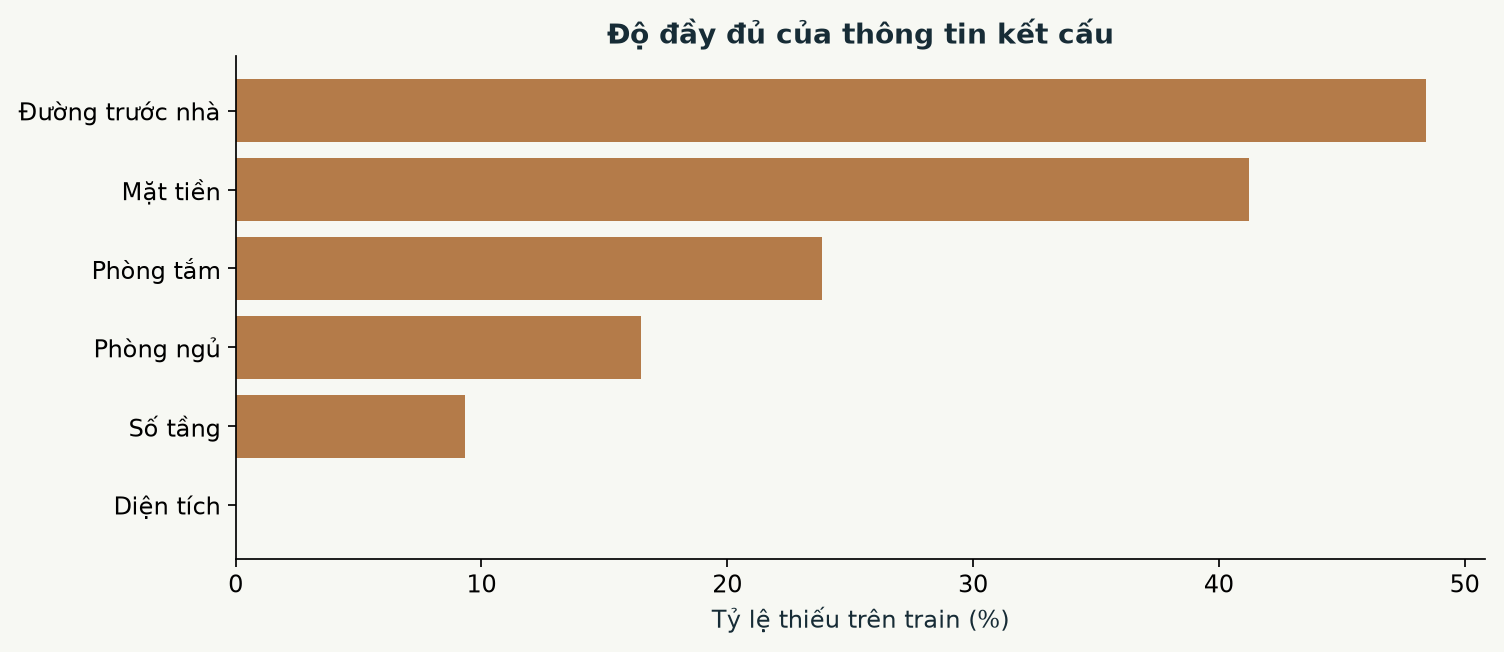

In [2]:
vn_split = json.loads((VN_ART / "split.json").read_text(encoding="utf-8"))
for i, left in enumerate(vn_split):
    for right in list(vn_split)[i+1:]:
        assert not set(vn_split[left]) & set(vn_split[right])
display(pd.DataFrame(vn_meta["splits"]).T)
print("Đầu vào ứng viên:",FEATURES)
display(Image(filename=str(VN_ART / "charts/missingness.png")))

## 2 Hồi quy tuyến tính và feature importance

OLS học log(VND), lấy log diện tích và chuẩn hóa sáu biến số. Các nhóm danh mục được one-hot. Độ quan trọng của một nhóm được đo bằng **mức tăng RMSE log trên validation khi bỏ nhóm đó và fit lại OLS**. Cách này so được cả số và danh mục, không xếp hạng hệ số thô có đơn vị khác nhau. Chỉ dùng train/validation để chọn biến; không dùng test.

Chạy lại phân tích dưới đây tái lập kết quả từ dữ liệu đã kiểm tra checksum. Hệ số có điều kiện, chưa chứng minh nhân quả.

OLS full {'rmse_log': 0.2451902863587861, 'rmse_vnd': 1460287622.9776614, 'r2_vnd': 0.5019053092190161, 'median_ape': 0.13778371116613475}


Without area 0.07175180701247402


Without

 bedroom_count 0.00013007255300870324


Without

 bathroom_count 0.0008589332363788948


... (8 outputs left out)

Without furniture_state -8.823699750581948e-07


Selected {'k': 6, 'features': ['area', 'district_name', 'floor_count', 'ward_name', 'legal_status', 'road_width'], 'validation': {'rmse_log': 0.24741566674956367, 'rmse_vnd': 1479939321.8116634, 'r2_vnd': 0.4884089677679029, 'median_ape': 0.1399497426379218}}


12 cột gốc gồm nhãn Price → 12 nhóm đầu vào sau xử lý → 166 cột thiết kế OLS


,label,delta_rmse_log,delta_rmse_vnd
0,Diện tích,7.175181e-02,3.212154e+08
1,Quận/huyện,3.907359e-02,1.344826e+08
2,Số tầng,9.681947e-03,5.249554e+07
3,Phường/xã,4.651458e-03,1.722498e+07
4,Pháp lý,2.923821e-03,4.358796e+06
5,Đường trước nhà,1.760181e-03,-4.853582e+06
6,Phòng tắm,8.589332e-04,5.908843e+06
7,Hướng nhà,1.481492e-04,9.628211e+05
8,Phòng ngủ,1.300726e-04,2.019866e+06
9,Mặt tiền,3.185399e-05,-3.187241e+05


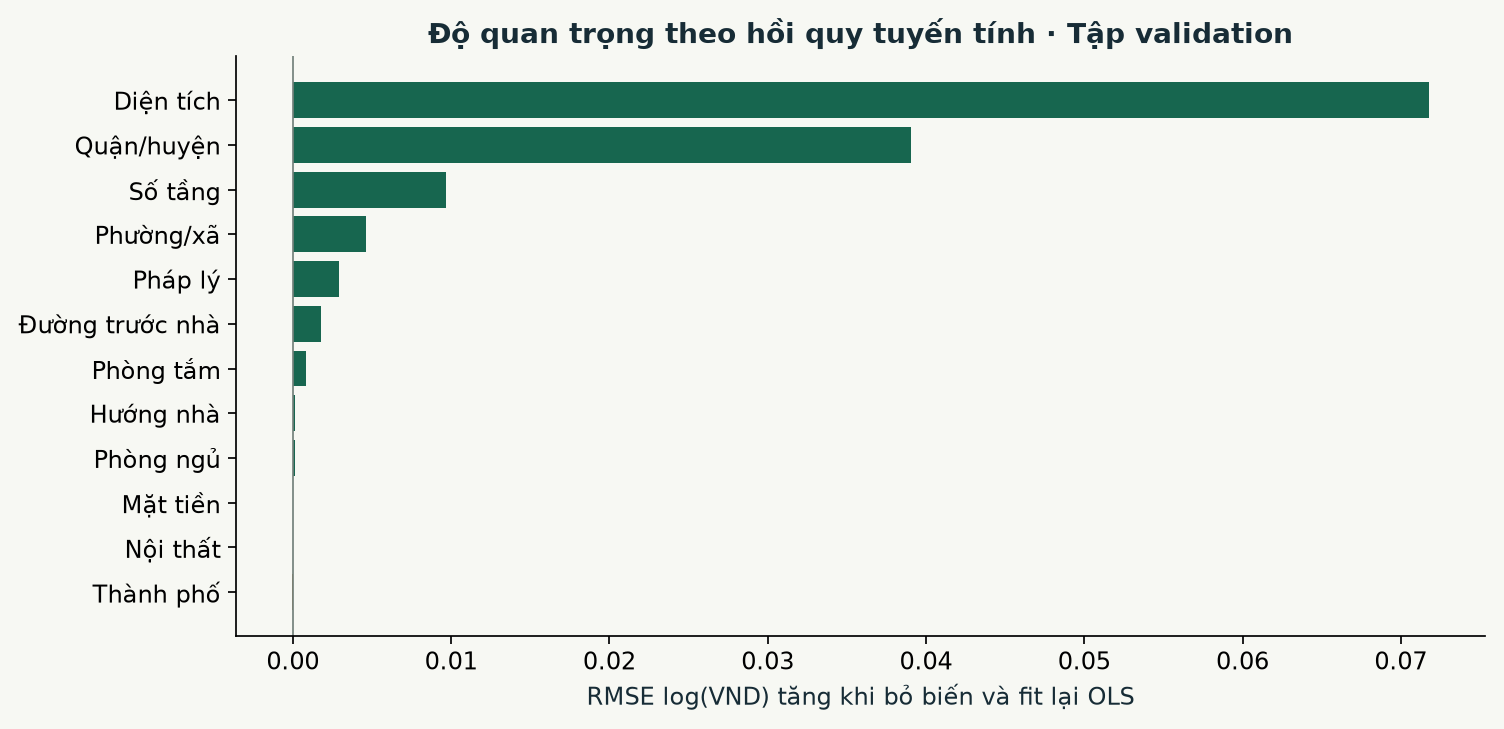

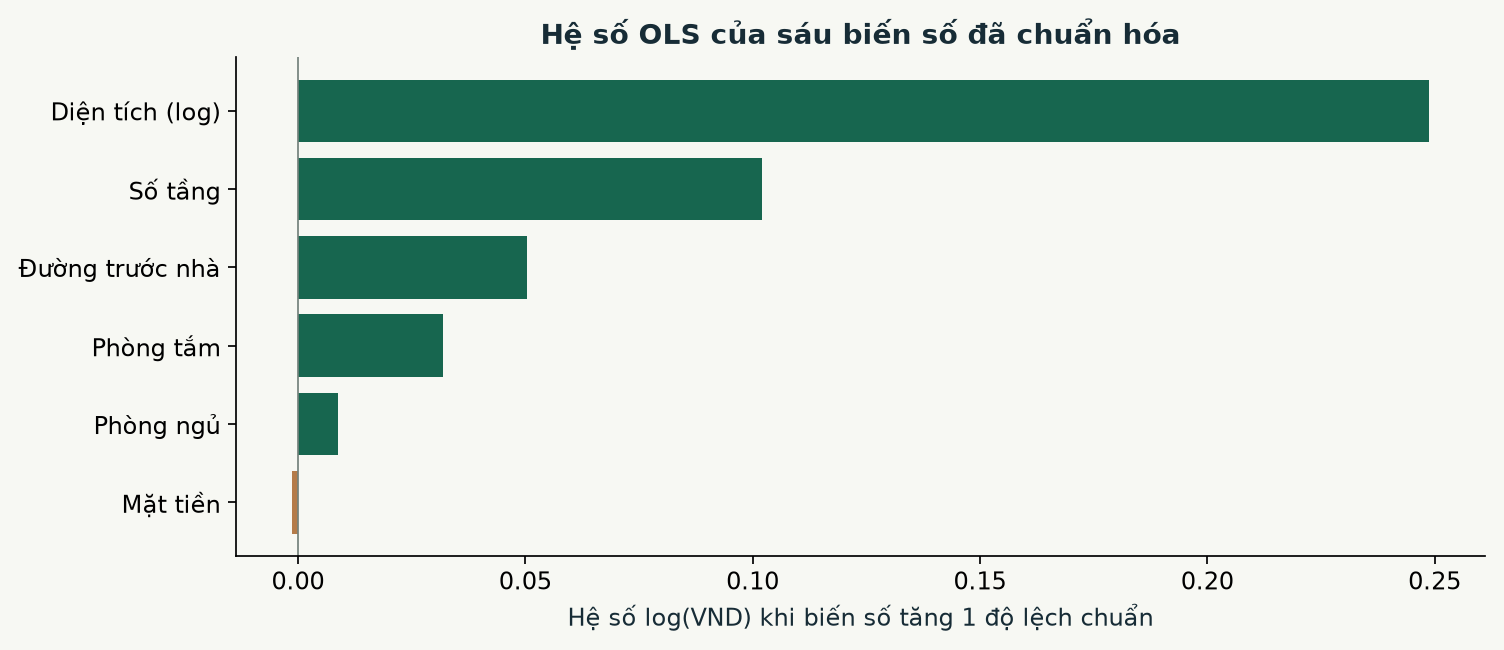

In [3]:
runpy.run_path(str(project.parent / "scripts/analyze_vietnam_linear.py"), run_name="__main__")
linear = json.loads((VN_ART / "linear_analysis.json").read_text(encoding="utf-8"))
print("12 cột gốc gồm nhãn Price →",linear["candidate_input_count"],"nhóm đầu vào sau xử lý →",linear["encoded_column_count"],"cột thiết kế OLS")
display(pd.DataFrame(linear["importance"])[["label","delta_rmse_log","delta_rmse_vnd"]])
display(Image(filename=str(VN_ART / "charts/linear_importance.png")))
display(Image(filename=str(VN_ART / "charts/linear_coefficients.png")))

## 3 Chọn số biến và lý do sử dụng

Chọn bộ nhỏ nhất trong các tiền tố thứ hạng có RMSE log không quá 1% so với bộ tốt nhất. Bộ lõi OLS có **6 biến**: diện tích, quận/huyện, số tầng, phường/xã, pháp lý và đường trước nhà. Diện tích mô tả quy mô; quận/phường mô tả vị trí; số tầng bổ sung kết cấu; pháp lý và chiều rộng đường bổ sung thông tin trong validation. Đây là liên hệ dự báo, chưa chứng minh nhân quả.

Số phòng tương quan với diện tích; thành phố có thông tin trùng quận/huyện. Ít thêm thông tin tuyến tính không có nghĩa là không liên quan đến giá. Ứng dụng phục vụ **XGBoost 12 đầu vào**, là mô hình phi tuyến riêng; chưa so XGBoost sáu biến với XGBoost 12 biến.

,rmse_log,rmse_vnd,r2_vnd,median_ape
k,,,,
1,0.361496,1.931851e+09,0.128269,0.221027
2,0.280360,1.612468e+09,0.392680,0.164899
3,0.256849,1.497288e+09,0.476344,0.151612
4,0.252259,1.481220e+09,0.487523,0.144335
5,0.249355,1.475616e+09,0.491394,0.143955
6,0.247416,1.479939e+09,0.488409,0.139950
7,0.245492,1.463331e+09,0.499827,0.137915
8,0.245323,1.462324e+09,0.500515,0.136418
9,0.245200,1.460184e+09,0.501976,0.138309


Bộ chọn: ['area', 'district_name', 'floor_count', 'ward_name', 'legal_status', 'road_width']


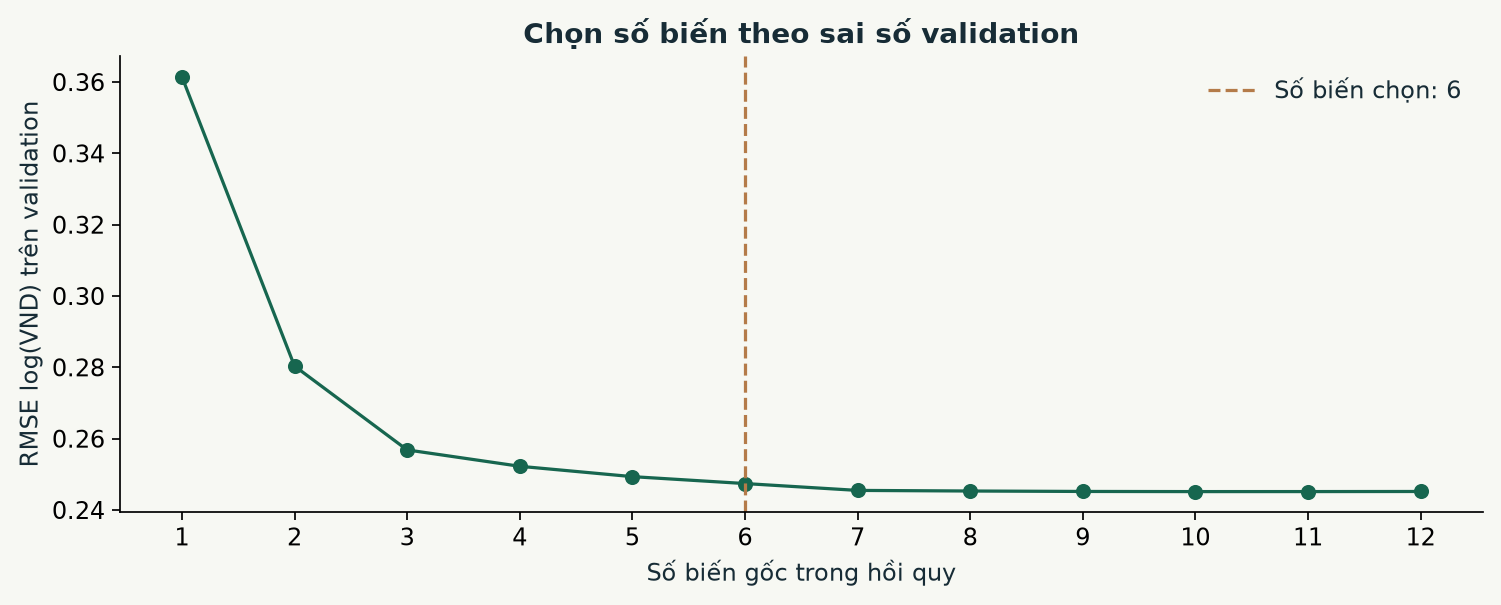

In [4]:
display(pd.DataFrame([{**row["validation"],"k":row["k"]} for row in linear["subsets"]]).set_index("k"))
print("Bộ chọn:",linear["selected"]["features"])
display(Image(filename=str(VN_ART / "charts/linear_selection.png")))

## 4 Biểu đồ về diện tích phòng và vị trí

Khám phá chỉ dùng train. Nguồn không có cột loại nhà nên các biểu đồ gộp bất động sản theo dataset. Trung vị giữa nhóm thể hiện quan hệ quan sát, không phải khoản tiền cộng cố định khi tăng một phòng. Đơn giá dùng diện tích khai báo, có thể là đất hoặc sàn tùy tin.

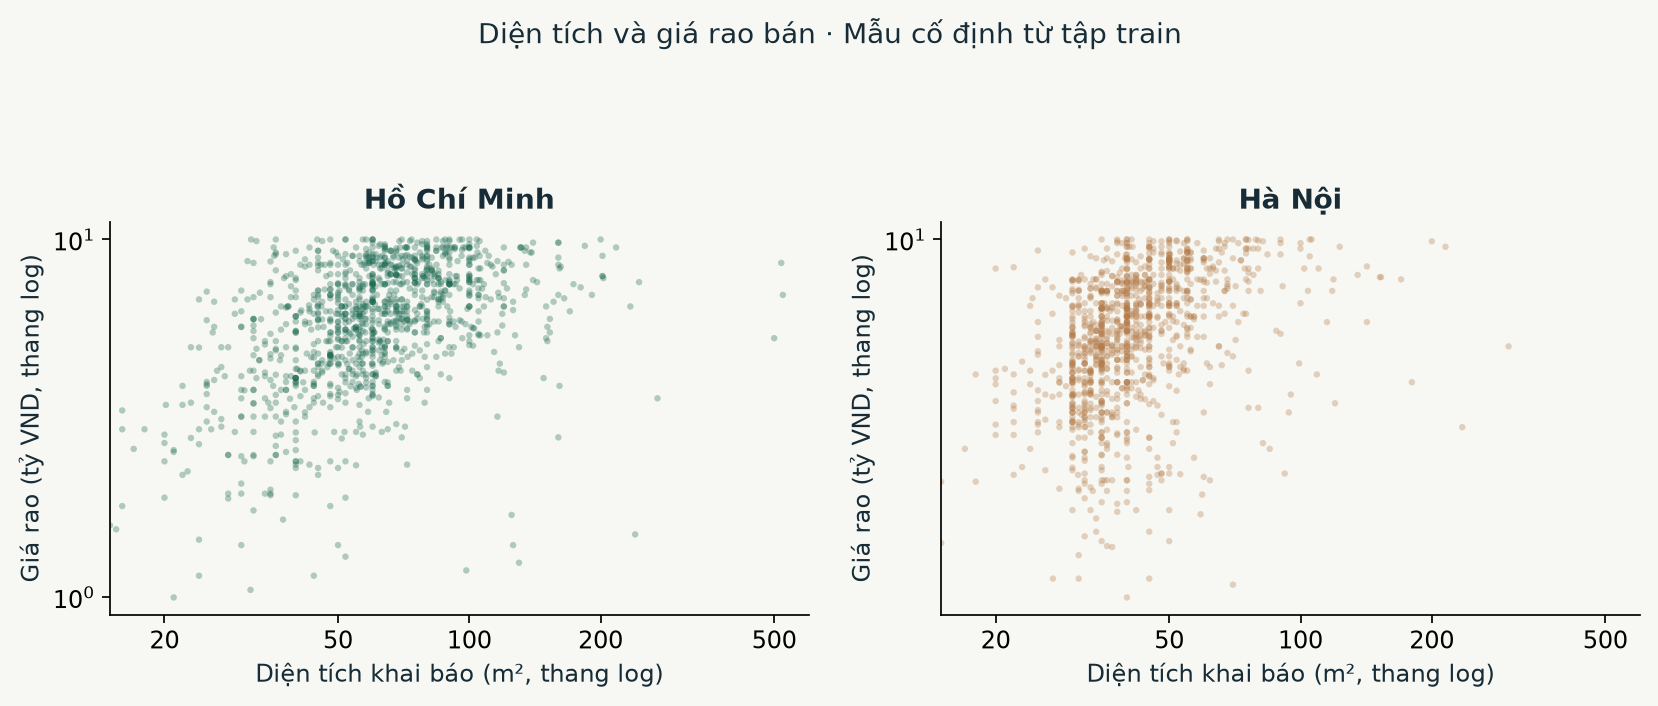

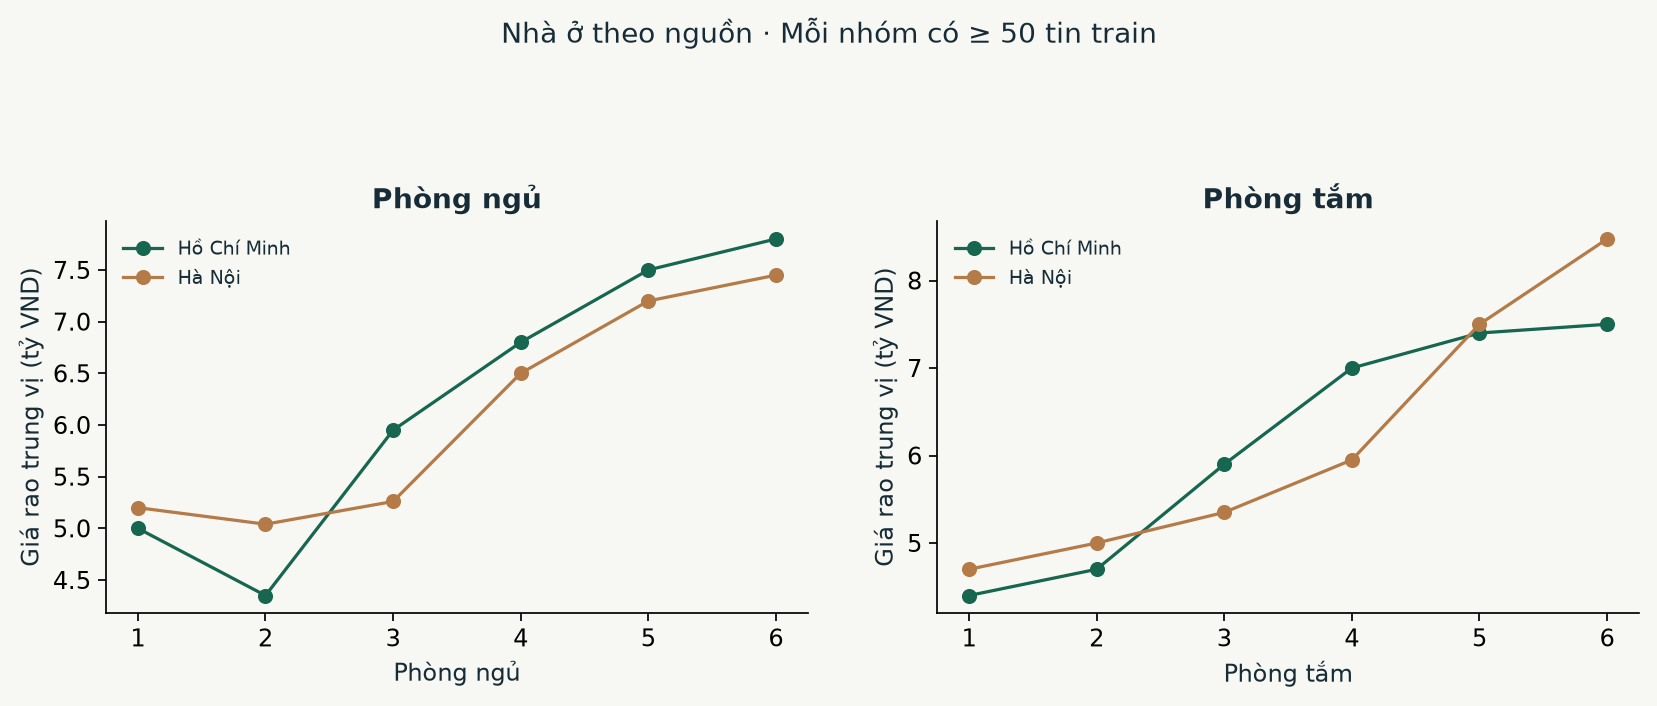

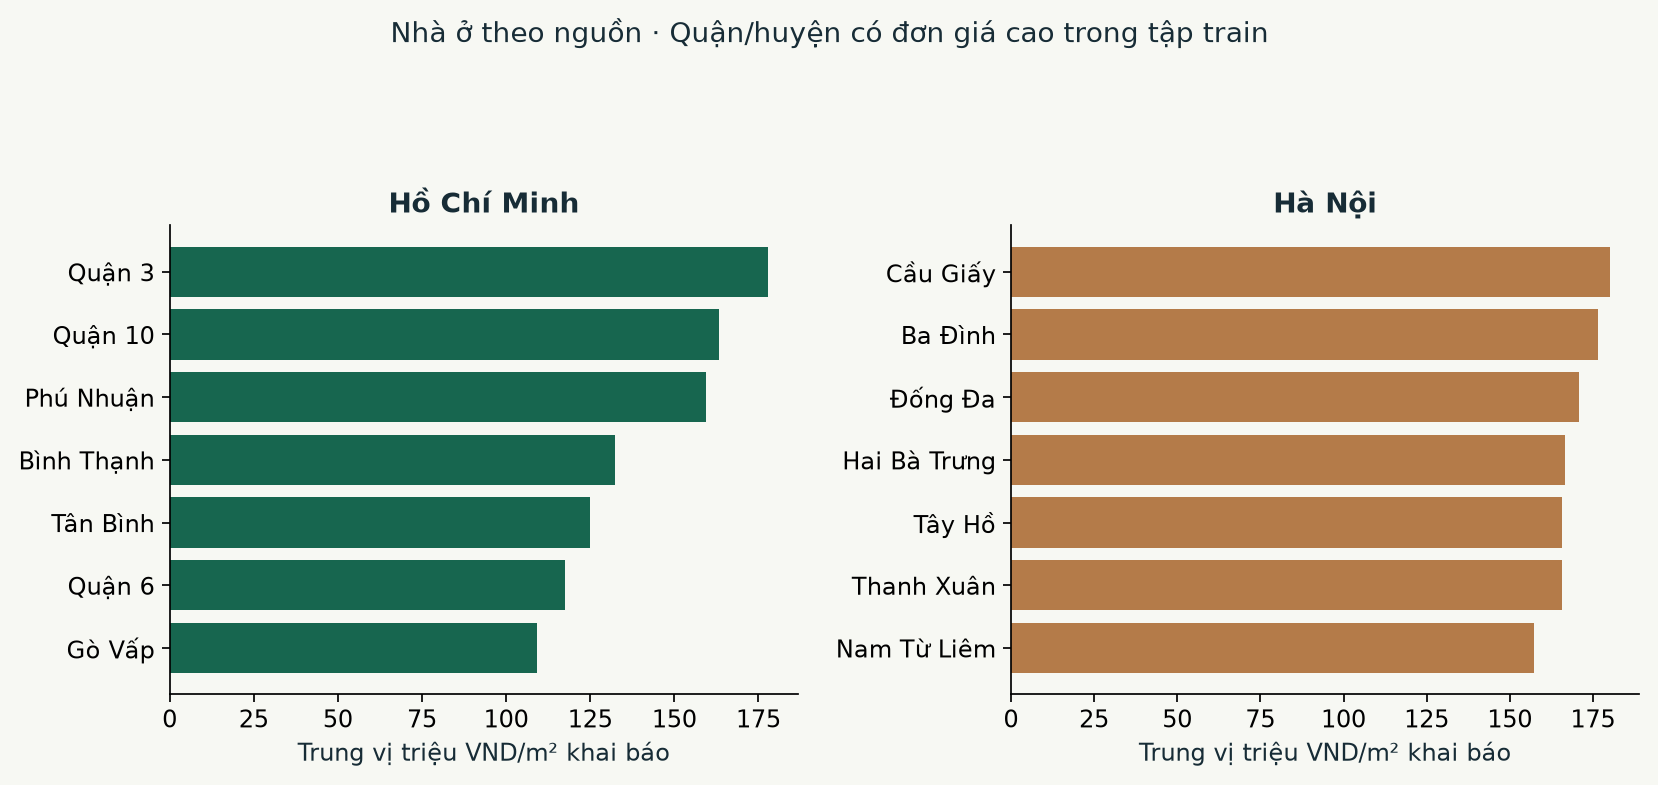

In [5]:
for chart in ["area_price","rooms","districts"]:
    display(Image(filename=str(VN_ART / "charts" / (chart+".png"))))

## 5 So sánh mô hình và kiểm thử cuối

XGBoost được chọn bằng validation, rồi fit train + validation. Calibration chỉ dùng hiệu chỉnh khoảng; test không chung nhóm địa chỉ–diện tích với phần fit. Không có ngày đăng để khẳng định test ở thời kỳ mới hơn. Các con số dưới đây được tính lại từ dự đoán của mô hình đã khóa.

,model,n,mae_vnd,rmse_vnd,r2,median_ape,within_20pct
0,Trung vị VND/m² theo khu vực,3271,1.466690e+09,2.621297e+09,-0.604973,0.175556,0.550902
1,XGBoost chưa dùng địa bàn,3271,1.232473e+09,1.579724e+09,0.417095,0.165109,0.585754
2,XGBoost thêm địa bàn,3271,9.390470e+08,1.242913e+09,0.639159,0.124600,0.721186


MAE VND       9.230267e+08
RMSE VND      1.225120e+09
R2 VND        6.435709e-01
MdAPE         1.207619e-01
Trong ±20%    7.287523e-01
dtype: float64

,dimension,label,n,mae_vnd,rmse_vnd,r2,median_ape,within_20pct,coverage_90
0,province_name,Hà Nội,1591,9.382583e+08,1.242672e+09,0.612360,0.125595,0.711502,0.902577
1,province_name,Hồ Chí Minh,1727,9.089946e+08,1.208724e+09,0.668619,0.117356,0.744644,0.890562


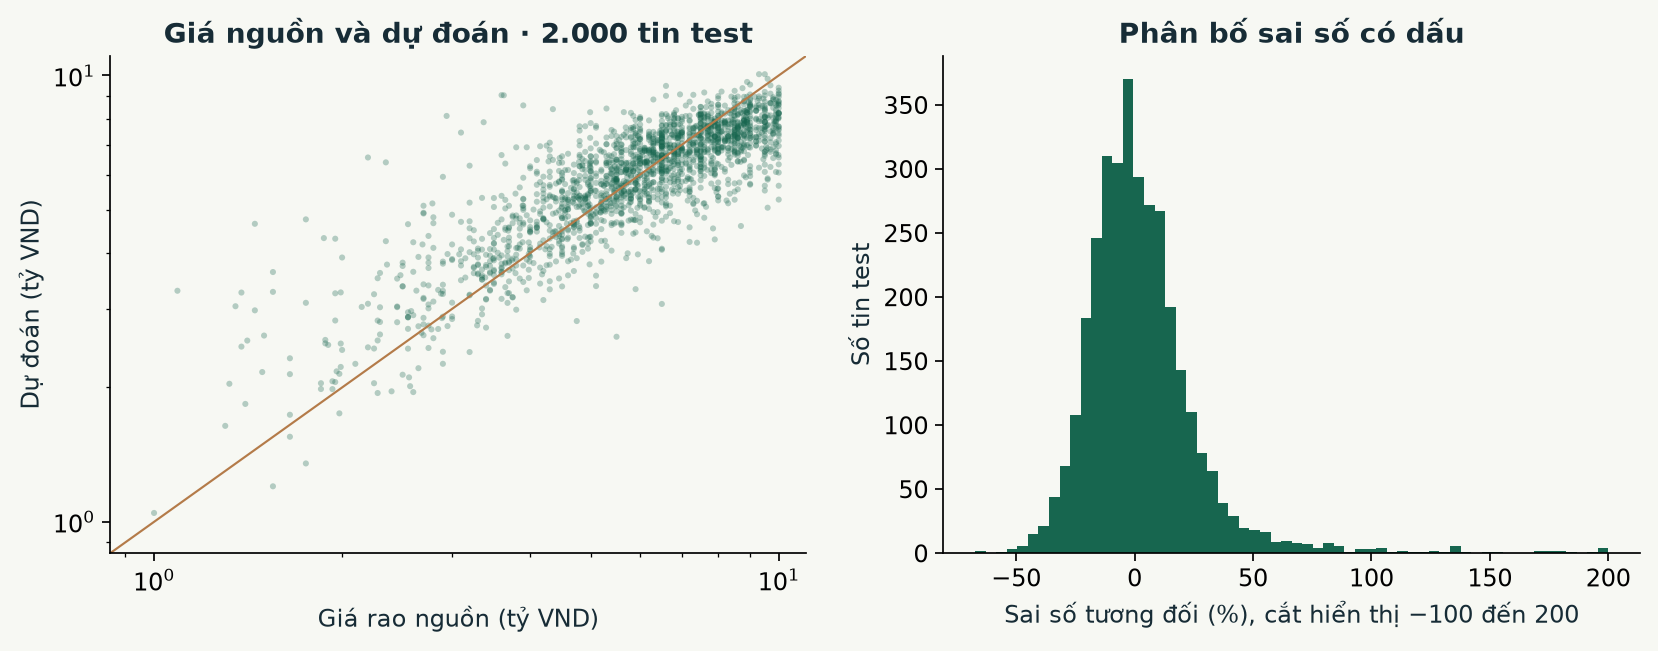

In [6]:
display(pd.DataFrame(vn_meta["validation_comparison"]))
vn_test = pd.read_csv(VN_ART / "test_predictions.csv", dtype={"district_name":str,"ward_name":str})
vn_pred = np.exp(load_bundle()["pipeline"].predict(normalize_features(vn_test)).astype(float))
assert np.allclose(vn_pred,vn_test.predicted_vnd,rtol=1e-6)
ape = np.abs(vn_pred - vn_test.price)/vn_test.price
display(pd.Series({"MAE VND":mean_absolute_error(vn_test.price,vn_pred),
                   "RMSE VND":np.sqrt(mean_squared_error(vn_test.price,vn_pred)),
                   "R2 VND":r2_score(vn_test.price,vn_pred),"MdAPE":np.median(ape),
                   "Trong ±20%":np.mean(ape<=.2)}))
display(pd.DataFrame(vn_meta["test_breakdown"]))
display(Image(filename=str(VN_ART / "charts/test_errors.png")))

## 6 Giải thích một căn nhà tại TP.HCM và Hà Nội

Chọn tin test có giá nguồn ở trung vị nhóm khai báo đủ phòng, trước khi xem sai số. TreeSHAP cộng trên log(VND), sau đó lấy hàm mũ để tái tạo dự đoán. Không diễn giải các thanh thành khoản VND cộng trực tiếp. Các tin đối chiếu từ train + validation, chưa phải giao dịch đã bán.

Hà Nội · Hà Đông {'area': 31.0, 'bedroom_count': 4.0, 'bathroom_count': 4.0, 'floor_count': 5.0, 'frontage_width': 3.3, 'road_width': 2.5, 'province_name': 'Hà Nội', 'district_name': 'Hà Đông', 'ward_name': 'Phường Vạn Phúc', 'house_direction': 'Tây - Nam', 'legal_status': 'Have certificate', 'furniture_state': 'Basic', 'reference_id': '0131f4af270516027cdc5f07'}


Giá rao nguồn VND                              5800000000.0
Giá dự đoán VND                           5209902510.762404
VND/m² khai báo                            168061371.314916
Khoảng 90%           [3770236464.159106, 7199305515.629577]
dtype: object

,feature,label,log_contribution
0,area,Diện tích,-0.261093
1,ward_name,Phường/xã,0.135309
2,road_width,Đường trước nhà,-0.096432
3,floor_count,Số tầng,0.056050
4,bathroom_count,Phòng tắm,0.022008
5,district_name,Quận/huyện,0.021410
6,furniture_state,Nội thất,-0.012969
7,bedroom_count,Phòng ngủ,0.011461
8,province_name,Thành phố,0.010007
9,legal_status,Pháp lý,0.006046


,listing_id,group_id,published_at,district_name,ward_name,area,bedroom_count,bathroom_count,price
0,ea0d61d945b1c55c55f9a415,4559aab5fe9409776e39de44,None,Hà Đông,Phường Vạn Phúc,31.0,4.0,4.0,6.200000e+09
1,fe7b33bc4e0542f1d23f226b,1c69e26058440766aeffa570,None,Hà Đông,Phường Vạn Phúc,31.0,4.0,4.0,6.100000e+09
2,2b35588faa42f070130d2b7b,f228a764da1a016f567dda59,None,Hà Đông,Phường Vạn Phúc,30.0,4.0,4.0,7.200000e+09
3,6339f909ead661196c094e94,e28b863161ffad9dfeae0e7d,None,Hà Đông,Phường Vạn Phúc,30.0,4.0,4.0,5.500000e+09
4,b0261794a1504be133b9232b,13aba4fc3e2828fb17be8427,None,Hà Đông,Phường Vạn Phúc,33.0,4.0,4.0,5.980000e+09


Hồ Chí Minh · Quận 2 {'area': 52.0, 'bedroom_count': 5.0, 'bathroom_count': 3.0, 'floor_count': 4.0, 'frontage_width': None, 'road_width': 5.0, 'province_name': 'Hồ Chí Minh', 'district_name': 'Quận 2', 'ward_name': 'Phường Bình Trưng Tây', 'house_direction': 'Không rõ', 'legal_status': 'Không rõ', 'furniture_state': 'Không rõ', 'reference_id': '801aaeca1aaba2e98c5dfb7c'}


Giá rao nguồn VND                              6300000000.0
Giá dự đoán VND                           6560432932.099627
VND/m² khai báo                            126162171.771147
Khoảng 90%           [4747571266.482813, 9065536427.105074]
dtype: object

,feature,label,log_contribution
0,floor_count,Số tầng,0.040667
1,area,Diện tích,0.036412
2,district_name,Quận/huyện,0.034123
3,bedroom_count,Phòng ngủ,0.019562
4,ward_name,Phường/xã,0.012730
5,legal_status,Pháp lý,-0.008760
6,province_name,Thành phố,-0.005762
7,frontage_width,Mặt tiền,-0.005678
8,bathroom_count,Phòng tắm,0.004988
9,road_width,Đường trước nhà,-0.002752


,listing_id,group_id,published_at,district_name,ward_name,area,bedroom_count,bathroom_count,price
0,5643eaf9cb936cf9614c2857,8008aadbeb9f0e4b42c52753,None,Quận 2,Phường Bình Trưng Tây,52.0,5.0,5.0,6.600000e+09
1,3e52134e8b21aec8388151ae,7d76ad40e6ead3548f41319b,None,Quận 2,Phường Bình Trưng Tây,51.5,3.0,3.0,6.300000e+09
2,37f3a589a0754e0da1811344,74d02bbbf648fb7f1d854909,None,Quận 2,Phường Bình Trưng Tây,51.5,4.0,4.0,6.300000e+09
3,adcbf3e64a9a12027d1441e9,8ee988cecfc61068a8a5c5a0,None,Quận 2,Phường Bình Trưng Tây,50.4,4.0,4.0,8.200000e+09
4,4971c72f000dccba5a6f724e,4389347b7c67153a16a10e32,None,Quận 2,Phường Bình Trưng Tây,60.0,5.0,4.0,8.200000e+09


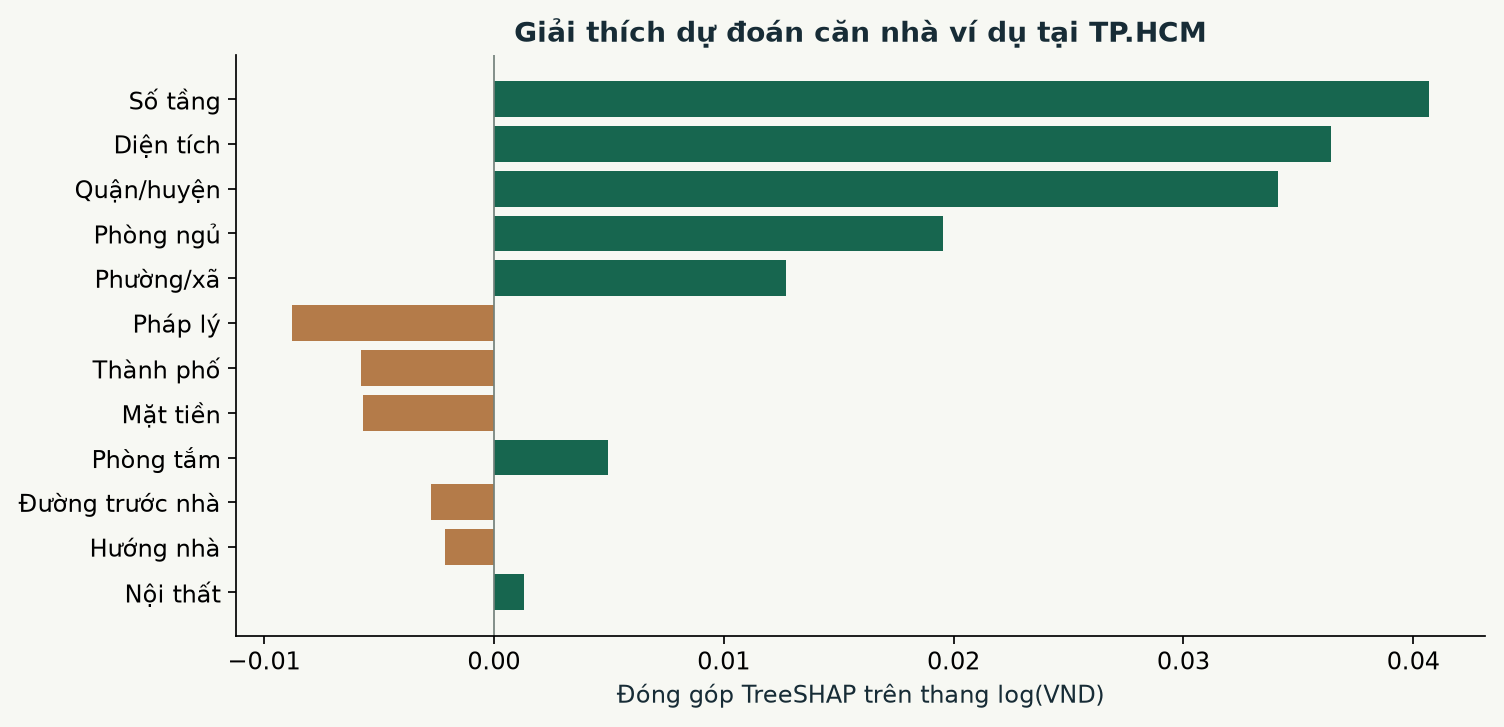

In [7]:
vn_examples = json.loads((VN_ART / "examples.json").read_text(encoding="utf-8"))
for case in vn_examples:
    result = estimate_property(case["input"])
    reconstructed = np.exp(result["base_log_vnd"] + sum(x["log_contribution"] for x in result["explanations"]))
    assert np.isclose(result["predicted_vnd"], reconstructed, rtol=5e-5)
    print(case["label"],case["input"])
    display(pd.Series({"Giá rao nguồn VND":case["asking_vnd"],"Giá dự đoán VND":result["predicted_vnd"],
                       "VND/m² khai báo":result["price_per_m2_vnd"],"Khoảng 90%":result["interval_90_vnd"]}))
    display(pd.DataFrame(result["explanations"]))
    display(pd.DataFrame(result["comparables"]))
display(Image(filename=str(VN_ART / "charts/example_explanation.png")))

## 7 Giới hạn và cách chạy

Nguồn chưa có tọa độ hoặc khoảng cách trường học/cửa hàng được xác minh, nên mô hình không dùng những biến này. Chưa có mã nhà thật, ngày đăng hoặc loại nhà; giá là giá rao; diện tích khai báo có thể chưa đồng nhất. Giá nguồn giữ lại từ 1 đến 11,5 tỷ VND; không suy rộng chất lượng sang phân khúc cao hơn. Khoảng 90% gộp không bảo đảm độ phủ từng thành phố.

Chạy `TieuLuan_CuoiKy/chay_ui.cmd`, mở http://127.0.0.1:8000. King County tham khảo tại `/kingcounty`. Huấn luyện lại Việt Nam: `scripts/huan_luyen.cmd`. Dữ liệu và model nằm trong `real_estate_ai/artifacts/vietnam/`. Không dùng dự đoán của người dùng làm nhãn huấn luyện.

Nguồn: [Nguyen Tien Nhan trên Kaggle](https://www.kaggle.com/datasets/nguyentiennhan/vietnam-housing-dataset-2024), phiên bản 8, CC0 Public Domain; [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html); [XGBoost prediction](https://xgboost.readthedocs.io/en/stable/prediction.html).